# Análisis espacial con H3: del mapa bonito al punto caliente real

**Avanzado · Jornada 3 · Bloque 3.2 · diapositivas repaso, maup, tasas, suavizado, moran, puntos-calientes y ejercicio-h3**

¿Dónde pierden la señal GPS las bicis de BiciCiudad, y es un patrón real o casualidad? Malla H3-8, MAUP, tasas con suavizado bayesiano empírico, Moran y LISA, y el ejercicio de cruzar los puntos calientes con la cobertura móvil y el emplazamiento.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

Las bicis de BiciCiudad pierden a veces la señal GPS: durante unos minutos el centro de control
no sabe dónde están. En un año hubo más de 21.000 pérdidas. ¿**Dónde** se pierde la señal, y lo que
se ve en el mapa **es real o es casualidad**?

Por el camino caen cuatro trampas: la unidad de área (MAUP), los conteos sin denominador, las
tasas de celdas con pocos viajes y los patrones que el ojo ve donde no los hay.

> **Mensaje clave del bloque:** un mapa sin contraste espacial es una opinión con colores.

## 1. Cargar y mirar los datos

`malla_h3/celdas.csv` tiene una fila por celda H3 de resolución 8 (hexágonos de unos 0,74 km²).
Cada celda lleva su distrito y su barrio (sintéticos), las capas de contexto que usaremos en el
ejercicio y dos cifras de un año (octubre de 2025 a septiembre de 2026): los **viajes que cruzan**
la celda y las **pérdidas de señal** registradas en ella.

In [2]:
%matplotlib inline
# Los gráficos, dentro del cuaderno; las tablas, con coma decimal.
pd.set_option("display.float_format", lambda x: estilo.num(x, 2))

celdas = pd.read_csv(DATOS / "malla_h3" / "celdas.csv")
print(f"{len(celdas)} celdas H3-8, {celdas['distrito'].nunique()} distritos y "
      f"{celdas['barrio'].nunique()} barrios")
print(f"Viajes que cruzan alguna celda: {estilo.num(celdas['viajes_que_cruzan'].sum())}")
print(f"Pérdidas de señal en un año: {estilo.num(celdas['perdidas_senal'].sum())}")
tasa_media = 1000 * celdas["perdidas_senal"].sum() / celdas["viajes_que_cruzan"].sum()
print(f"Tasa media de la ciudad: {estilo.num(tasa_media, 2)} pérdidas por cada 1.000 viajes")
celdas.head()

595 celdas H3-8, 8 distritos y 38 barrios
Viajes que cruzan alguna celda: 9.956.439
Pérdidas de señal en un año: 21.020
Tasa media de la ciudad: 2,11 pérdidas por cada 1.000 viajes


,h3,lat,lon,distrito,barrio,cobertura_dbm,cobertura,pasos_subterraneos,soportales,aparcamientos_subterraneos,viajes_que_cruzan,perdidas_senal
0,88356520c9fffff,"39,98","-12,66",Jardín Botánico,Jardín Botánico 2,-84,buena,0,False,0,243,0
1,88356520cbfffff,"39,97","-12,65",Jardín Botánico,Jardín Botánico 1,-85,buena,0,False,0,163,0
2,88356520d1fffff,"39,96","-12,64",Jardín Botánico,Jardín Botánico 1,-85,buena,0,False,0,281,0
3,88356520d3fffff,"39,95","-12,64",Jardín Botánico,Jardín Botánico 1,-87,buena,0,False,0,854,2
4,88356520d9fffff,"39,96","-12,64",Jardín Botánico,Jardín Botánico 1,-87,buena,0,False,0,937,2


Fijaos en lo distintas que son las celdas: unas las cruzan cientos de miles de viajes al año y otras
menos de doscientos. Eso va a importar.

In [3]:
celdas["viajes_que_cruzan"].describe().round(0)

count       595,00
mean     16.734,00
std      49.350,00
min          84,00
25%         504,00
50%         940,00
75%       2.488,00
max     416.022,00
Name: viajes_que_cruzan, dtype: float64

Para dibujar: cada índice H3 se convierte en su hexágono con `h3.cell_to_boundary`. Las coordenadas
son inventadas y caen en pleno Atlántico, así que dibujamos en kilómetros respecto al centro de la
ciudad, sin mapa de fondo. Esta celda solo prepara el dibujo.

In [4]:
import h3
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap

# Las coordenadas son inventadas (en pleno Atlántico): dibujamos en km respecto al centro
# de la ciudad, sin mapa de fondo.
CENTRO_LAT, CENTRO_LON = 40.0, -12.5
KM_POR_GRADO_LAT = 110.574
KM_POR_GRADO_LON = 111.320 * np.cos(np.radians(CENTRO_LAT))


def a_km(lat, lon):
    """De grados a km al este (x) y al norte (y) del centro."""
    return ((np.asarray(lon) - CENTRO_LON) * KM_POR_GRADO_LON,
            (np.asarray(lat) - CENTRO_LAT) * KM_POR_GRADO_LAT)


# El hexágono de cada celda, en km.
hexagonos = []
for celda in celdas["h3"]:
    lat, lon = zip(*h3.cell_to_boundary(celda))
    x, y = a_km(lat, lon)
    hexagonos.append(np.column_stack([x, y]))
celdas["x"], celdas["y"] = a_km(celdas["lat"], celdas["lon"])

AZULES = LinearSegmentedColormap.from_list("azules", ["#E4EFF6", "#7FB8DE", estilo.AZUL, "#0B2A3F"])
SIN_DATO = "#E3E9ED"


def pintar_mapa(ax, colores, titulo=""):
    """Pinta las 595 celdas con los colores dados (uno por celda)."""
    ax.add_collection(PolyCollection(hexagonos, facecolors=colores, edgecolors="white", linewidths=0.4))
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo, fontsize=11, loc="center", pad=6)

## 2. Mismo dato, tres mapas: el problema de la unidad de área (MAUP)

Calculamos la tasa de pérdidas por cada 1.000 viajes **por distrito, por barrio y por celda**, con
los mismos datos. En naranja, la peor unidad de cada mapa. Para no premiar el ruido, solo cuentan los
barrios con 5.000 viajes o más y las celdas con 1.000 o más (las grises se quedan fuera).

Cambiad los mínimos y mirad cómo cambia la «peor zona».

     8 distritos: peor Lonja, 2,71 por 1.000
      38 barrios: peor Paseo del Río 1, 3,55 por 1.000
 595 celdas H3-8: peor una celda de Ayuntamiento 3, 13,2 por 1.000


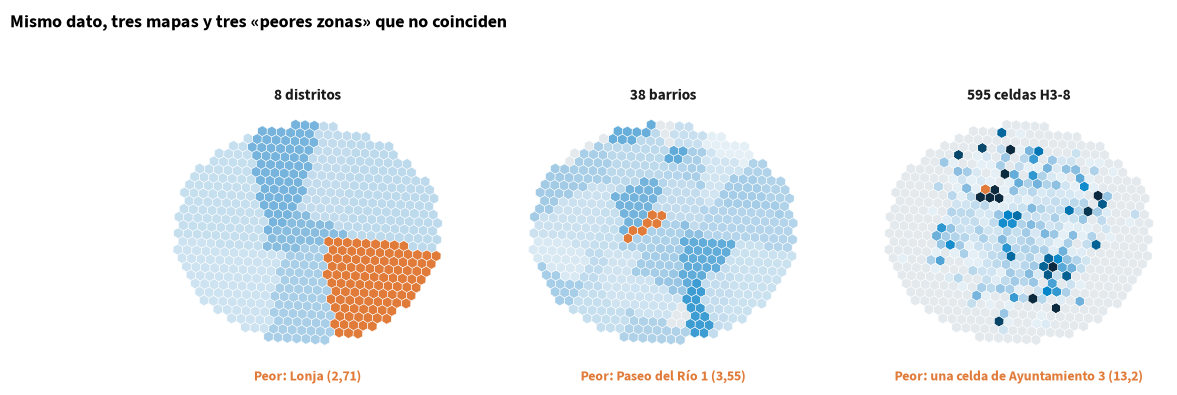

In [5]:
MINIMO_VIAJES = {"distrito": 0, "barrio": 5000, "h3": 1000}  # ← viajes mínimos para entrar en el ranking


def tasa_por(unidad, minimo):
    """Pérdidas por 1.000 viajes de cada unidad (distrito, barrio o celda)."""
    suma = celdas.groupby(unidad)[["viajes_que_cruzan", "perdidas_senal"]].sum()
    suma["tasa_por_mil"] = 1000 * suma["perdidas_senal"] / suma["viajes_que_cruzan"]
    return suma[suma["viajes_que_cruzan"] >= minimo]


fig, ejes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (unidad, nombre) in zip(ejes, [("distrito", "8 distritos"), ("barrio", "38 barrios"),
                                       ("h3", "595 celdas H3-8")]):
    tasas = tasa_por(unidad, MINIMO_VIAJES[unidad])
    peor = tasas["tasa_por_mil"].idxmax()
    # Cada celda toma el color de la unidad a la que pertenece.
    tasa_celda = celdas[unidad].map(tasas["tasa_por_mil"])
    colores = [SIN_DATO if pd.isna(t) else (estilo.NARANJA if u == peor else AZULES((t - 1.2) / 3.3 * 0.85))
               for t, u in zip(tasa_celda, celdas[unidad])]
    pintar_mapa(ax, colores, nombre)
    if unidad == "h3":
        peor_texto = f"una celda de {celdas.loc[celdas['h3'] == peor, 'barrio'].iloc[0]}"
    else:
        peor_texto = peor
    valor = tasas.loc[peor, "tasa_por_mil"]
    valor_texto = estilo.num(valor, 2 if valor < 10 else 1)
    ax.text(0.5, -0.04, f"Peor: {peor_texto} ({valor_texto})",
            transform=ax.transAxes, ha="center", va="top", color=estilo.NARANJA, weight="bold")
    print(f"{nombre:>16}: peor {peor_texto}, {valor_texto} por 1.000")
fig.suptitle("Mismo dato, tres mapas y tres «peores zonas» que no coinciden", x=0.01, ha="left",
             fontsize=13, weight="bold")
plt.show()

Tres mapas, tres «peores zonas», y ninguna coincide. El distrito mezcla un problema real con mucho
terreno normal y lo diluye; el barrio depende de por dónde pasó la línea que alguien dibujó un día; la
celda es la más fina, pero también la más ruidosa. **Si la decisión depende de la unidad elegida, la
conclusión no es robusta.**

## 3. Conteos frente a tasas

El mapa que haría cualquiera con prisa cuenta las pérdidas de cada celda. Pero por el centro pasan
muchísimas más bicis: un conteo dice sobre todo dónde hay tráfico. Comparad las ocho celdas con más
pérdidas con las ocho con más pérdidas **por cada 1.000 viajes** (solo celdas con 1.000 viajes o más).

In [6]:
cuantas = 8  # ← cuántas celdas mirar en cada lista
columnas = ["distrito", "barrio", "viajes_que_cruzan", "perdidas_senal", "tasa_por_mil"]
celdas["tasa_por_mil"] = 1000 * celdas["perdidas_senal"] / celdas["viajes_que_cruzan"]

print("Las que más pérdidas tienen (conteo):")
display(celdas.nlargest(cuantas, "perdidas_senal")[columnas])
print("Las que más pérdidas tienen por cada 1.000 viajes (tasa):")
display(celdas[celdas["viajes_que_cruzan"] >= 1000].nlargest(cuantas, "tasa_por_mil")[columnas])

Las que más pérdidas tienen (conteo):


,distrito,barrio,viajes_que_cruzan,perdidas_senal,tasa_por_mil
206,Paseo del Río,Paseo del Río 1,371008,1416,"3,82"
197,Ayuntamiento,Ayuntamiento 3,138943,968,"6,97"
273,Paseo del Río,Paseo del Río 2,381221,933,"2,45"
204,Paseo del Río,Paseo del Río 1,200291,821,"4,10"
275,Paseo del Río,Paseo del Río 2,416022,776,"1,87"
192,Intermodal,Intermodal 3,275241,673,"2,45"
368,Paseo del Río,Paseo del Río 1,149108,522,"3,50"
362,Ayuntamiento,Ayuntamiento 3,235044,507,"2,16"


Las que más pérdidas tienen por cada 1.000 viajes (tasa):


,distrito,barrio,viajes_que_cruzan,perdidas_senal,tasa_por_mil
198,Ayuntamiento,Ayuntamiento 3,2417,32,"13,24"
257,Lonja,Lonja 1,9580,94,"9,81"
196,Ayuntamiento,Ayuntamiento 3,3038,27,"8,89"
292,Ayuntamiento,Ayuntamiento 3,55834,423,"7,58"
197,Ayuntamiento,Ayuntamiento 3,138943,968,"6,97"
199,Ayuntamiento,Ayuntamiento 3,36716,244,"6,65"
454,Ayuntamiento,Ayuntamiento 4,1039,6,"5,77"
115,Biblioteca,Biblioteca 3,1088,6,"5,51"


En conteos manda el centro (Paseo del Río, Ayuntamiento, Intermodal), con cientos de miles de viajes.
En tasas salen otros sitios, sobre todo un grupo de Ayuntamiento al noroeste del centro. Para saber
dónde mandar a alguien a revisar, interesa la tasa: el conteo ya sabíamos dónde iba a ser alto.

Lo mismo pasa con la lista de 50 bicis del repaso, que caía «la mayoría en el centro». Mirad dónde
están **todas** las bicis al cierre de septiembre: el centro tiene más de todo.

In [7]:
ultima = pd.read_csv(DATOS / "telemetria" / "ultima_posicion.csv")
bicis = ultima.merge(celdas[["h3", "distrito"]], on="h3")
reparto = bicis["distrito"].value_counts()
(100 * reparto / reparto.sum()).round(1).rename("% de las 2.000 bicis").to_frame()

,% de las 2.000 bicis
distrito,
Paseo del Río,"39,40"
Intermodal,"19,00"
Ayuntamiento,"16,10"
Biblioteca,"7,90"
Auditorio,"7,60"
Polideportivo,"4,40"
Lonja,"4,00"
Jardín Botánico,"1,60"


## 4. Con pocos viajes, la tasa exagera: suavizado bayesiano empírico

La tasa bruta más alta de la ciudad es la de una celda de las afueras con 195 viajes y 3 pérdidas:
15,4 por 1.000. Una pérdida más o menos la movería cinco puntos. El suavizado bayesiano empírico
hace algo muy sensato: **si sabes poco de una celda, supón que se parece a la media; si sabes mucho,
créete sus datos.**

Cada tasa suavizada es una media ponderada entre la tasa de la celda y la media de la ciudad. El
peso de la celda depende de cuánto varían de verdad las celdas entre sí y de cuántos viajes tiene:

- tasa suavizada = media + peso × (tasa bruta − media)
- peso = varianza entre celdas / (varianza entre celdas + media / viajes de la celda)

La varianza entre celdas se estima con los propios datos (método de los momentos de Marshall, 1991):
la varianza de las tasas, ponderada por viajes, menos la parte que se explica por el azar de contar
pocos casos.

In [8]:
viajes = celdas["viajes_que_cruzan"]
perdidas = celdas["perdidas_senal"]
bruta = perdidas / viajes
media = perdidas.sum() / viajes.sum()

# Cuánto varían las tasas «de verdad» entre celdas: la varianza observada (ponderada por
# viajes) menos el ruido de contar pocos casos (Poisson). Si saliera negativa, sería 0.
varianza_entre = (viajes * (bruta - media) ** 2).sum() / viajes.sum() - media / viajes.mean()
varianza_entre = max(varianza_entre, 0)

# El peso de cada celda crece con sus viajes.
celdas["peso_propio"] = varianza_entre / (varianza_entre + media / viajes)
celdas["tasa_bruta"] = 1000 * bruta
celdas["tasa_suavizada"] = 1000 * (media + celdas["peso_propio"] * (bruta - media))

print(f"Media de la ciudad: {estilo.num(1000 * media, 2)} por 1.000 viajes")
print(f"Tasa suavizada: de {estilo.num(celdas['tasa_suavizada'].min(), 2)} "
      f"a {estilo.num(celdas['tasa_suavizada'].max(), 2)}")
# Las diez tasas brutas más altas: casi todas de celdas con pocos viajes.
celdas.nlargest(10, "tasa_bruta")[["barrio", "viajes_que_cruzan", "perdidas_senal", "tasa_bruta",
                                    "peso_propio", "tasa_suavizada"]]

Media de la ciudad: 2,11 por 1.000 viajes
Tasa suavizada: de 0,82 a 8,68


,barrio,viajes_que_cruzan,perdidas_senal,tasa_bruta,peso_propio,tasa_suavizada
461,Polideportivo 2,195,3,"15,38","0,10","3,50"
198,Ayuntamiento 3,2417,32,"13,24","0,59","8,68"
16,Polideportivo 1,414,5,"12,08","0,20","4,09"
41,Jardín Botánico 2,84,1,"11,90","0,05","2,58"
24,Polideportivo 4,664,7,"10,54","0,28","4,50"
257,Lonja 1,9580,94,"9,81","0,85","8,67"
152,Jardín Botánico 1,212,2,"9,43","0,11","2,93"
129,Lonja 2,107,1,"9,35","0,06","2,55"
196,Ayuntamiento 3,3038,27,"8,89","0,64","6,48"
6,Jardín Botánico 1,122,1,"8,20","0,07","2,52"


La celda de Polideportivo baja de 15,4 a 3,5: sigue por encima de la media, pero ya no es un récord.
Las celdas con decenas de miles de viajes casi no se mueven (su peso propio es casi 1). **A partir de
aquí trabajamos con la tasa suavizada.**

## 5. ¿Se agrupan? El índice de Moran

Moran compara el valor de cada celda con el de sus vecinas. Con H3 la vecindad es fácil: cada
hexágono tiene seis vecinos a la misma distancia (menos en el borde de la ciudad). `h3.grid_disk(celda, 1)`
devuelve la celda y sus vecinas.

In [9]:
posicion = {c: i for i, c in enumerate(celdas["h3"])}
vecinos = [[posicion[v] for v in h3.grid_disk(c, 1) if v != c and v in posicion]
           for c in celdas["h3"]]
pd.Series([len(v) for v in vecinos]).value_counts().rename("celdas").rename_axis("vecinas").to_frame()

,celdas
vecinas,
6,508
4,35
3,29
5,23


El cálculo, paso a paso:

1. Se tipifica la tasa suavizada: `z` = (tasa − media) / desviación típica.
2. Para cada celda, la media de `z` en sus vecinas (el «retardo espacial»).
3. **I de Moran** = media de `z × retardo`. Positivo: las parecidas se juntan. Cerca de 0: sin patrón.

¿Cómo sabemos si el valor es «cerca de 0»? Barajamos las tasas entre las celdas cientos de veces y
miramos cuántas veces el azar da un índice tan alto como el nuestro: es el p-valor por permutaciones.
La semilla es la que usó el generador de los datos, para que salga lo mismo que en la diapositiva.

In [10]:
N_PERMUTACIONES = 499          # ← barajados del contraste
SEMILLA_MORAN = [2026, 9, 3]   # ← la misma que el generador de los datos


def retardo(z):
    """Media de z en las vecinas de cada celda."""
    return np.array([z[v].mean() for v in vecinos])


tasa = celdas["tasa_suavizada"].to_numpy()
z = (tasa - tasa.mean()) / tasa.std()
moran = (z * retardo(z)).mean()

azar = np.random.default_rng(SEMILLA_MORAN)
moran_azar = []
for _ in range(N_PERMUTACIONES):
    z_barajada = azar.permutation(z)
    moran_azar.append((z_barajada * retardo(z_barajada)).mean())
moran_azar = np.array(moran_azar)
p_moran = ((moran_azar >= moran).sum() + 1) / (N_PERMUTACIONES + 1)
print(f"I de Moran = {estilo.num(moran, 2)}; p = {estilo.num(p_moran, 3)} con {N_PERMUTACIONES} permutaciones")
print(f"El mayor I que dio el azar: {estilo.num(moran_azar.max(), 2)}")

I de Moran = 0,23; p = 0,002 con 499 permutaciones
El mayor I que dio el azar: 0,09


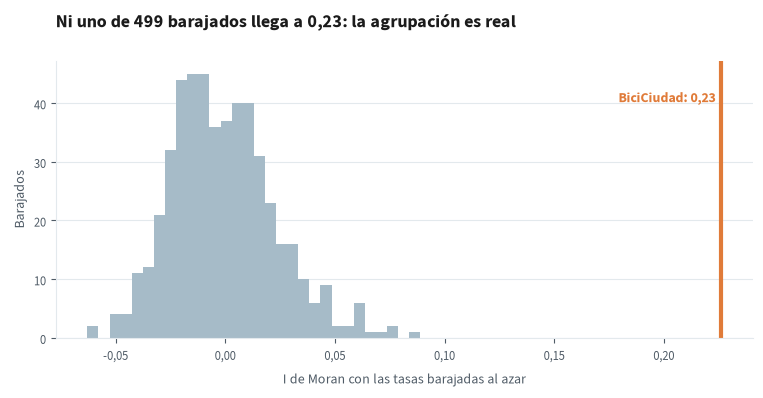

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(moran_azar, bins=30, color=estilo.GRIS)
ax.axvline(moran, color=estilo.NARANJA, lw=3)
ax.text(moran, ax.get_ylim()[1] * 0.9, f"BiciCiudad: {estilo.num(moran, 2)}  ", color=estilo.NARANJA,
        weight="bold", va="top", ha="right")
ax.set_title(f"Ni uno de {N_PERMUTACIONES} barajados llega a {estilo.num(moran, 2)}: la agrupación es real")
ax.set_xlabel("I de Moran con las tasas barajadas al azar")
ax.set_ylabel("Barajados")
estilo.formato_eje(ax, "x", 2)
plt.show()

## 6. ¿Dónde? LISA, Moran celda a celda

Moran dice que hay agrupación, pero no dónde. LISA (indicadores locales de asociación espacial) da a
cada celda su propio índice, `z × retardo`, y su propio p-valor: se barajan solo sus vecinas (999
veces, sacadas al azar del resto de celdas) y se mira cuántas veces el azar da algo tan extremo.

Con p < 0,05, cada celda recibe una etiqueta: **alto-alto** (punto caliente: alta y con vecinas
altas), **bajo-bajo** (punto frío) o atípica (alto-bajo, bajo-alto). Getis-Ord es una alternativa con
la misma idea; aquí usamos LISA.

In [12]:
N_PERMUTACIONES_LISA = 999   # ← barajados por celda
UMBRAL_P = 0.05              # ← nivel de significación de cada celda
SEMILLA_LISA = [2026, 9, 2]  # ← la misma que el generador de los datos

azar = np.random.default_rng(SEMILLA_LISA)
lag = retardo(z)
i_local = z * lag
p_local = np.ones(len(z))
for i, vecinas in enumerate(vecinos):
    k = len(vecinas)
    otras = np.delete(np.arange(len(z)), i)  # todas menos la propia celda
    # 999 juegos de k «vecinas» al azar, y el índice local que darían.
    falsas = z[otras[azar.integers(0, len(otras), (N_PERMUTACIONES_LISA, k))]].mean(axis=1)
    i_falso = z[i] * falsas
    if i_local[i] >= 0:
        extremos = (i_falso >= i_local[i]).sum()
    else:
        extremos = (i_falso <= i_local[i]).sum()
    p_local[i] = (extremos + 1) / (N_PERMUTACIONES_LISA + 1)

celdas["lisa"] = np.select(
    [p_local >= UMBRAL_P, (z > 0) & (lag > 0), (z > 0) & (lag <= 0), (z <= 0) & (lag < 0)],
    ["sin patrón", "alto-alto", "alto-bajo", "bajo-bajo"], default="bajo-alto")
celdas["lisa"].value_counts().to_frame()

,count
lisa,
sin patrón,520
bajo-bajo,37
alto-alto,15
alto-bajo,12
bajo-alto,11


LISA hace **una prueba por celda**: casi seiscientas pruebas al 5 %. Unas cuantas saldrán
significativas por puro azar (las gominolas de la Jornada 1 también viven en los mapas). Un grupo de
cinco o seis celdas vecinas es mucho más difícil de fabricar por casualidad que una celda suelta.

Juntamos las celdas alto-alto que se tocan en grupos y los numeramos de fuera hacia dentro, como en la
diapositiva.

In [13]:
import networkx as nx

calientes = set(celdas.loc[celdas["lisa"] == "alto-alto", "h3"])
contactos = nx.Graph()
contactos.add_nodes_from(calientes)
for c in calientes:
    contactos.add_edges_from((c, v) for v in h3.grid_disk(c, 1) if v in calientes and v != c)

grupos = []
for componente in nx.connected_components(contactos):
    sel = celdas["h3"].isin(componente)
    grupos.append({"celdas": len(componente), "x_km": celdas.loc[sel, "x"].mean(),
                   "y_km": celdas.loc[sel, "y"].mean(), "miembros": componente})
grupos = pd.DataFrame(grupos)
grupos["km_al_centro"] = np.hypot(grupos["x_km"], grupos["y_km"])
# Grupos de dos o más celdas, numerados de fuera hacia dentro; las celdas solas, «suelta».
grupos["suelta"] = grupos["celdas"] < 2
grupos = grupos.sort_values(["suelta", "km_al_centro"], ascending=[True, False]).reset_index(drop=True)
grupos["grupo"] = [str(i + 1) if n > 1 else "suelta" for i, n in enumerate(grupos["celdas"])]

celdas["grupo"] = "resto de la ciudad"
for g in grupos.itertuples():
    celdas.loc[celdas["h3"].isin(g.miembros), "grupo"] = g.grupo
grupos[["grupo", "celdas", "x_km", "y_km", "km_al_centro"]]

,grupo,celdas,x_km,y_km,km_al_centro
0,1,5,"-3,62","4,28","5,61"
1,2,6,"2,84","-3,09","4,20"
2,3,2,"-1,53","1,69","2,28"
3,suelta,1,"-11,83","6,95","13,72"
4,suelta,1,"-12,02","1,85","12,16"


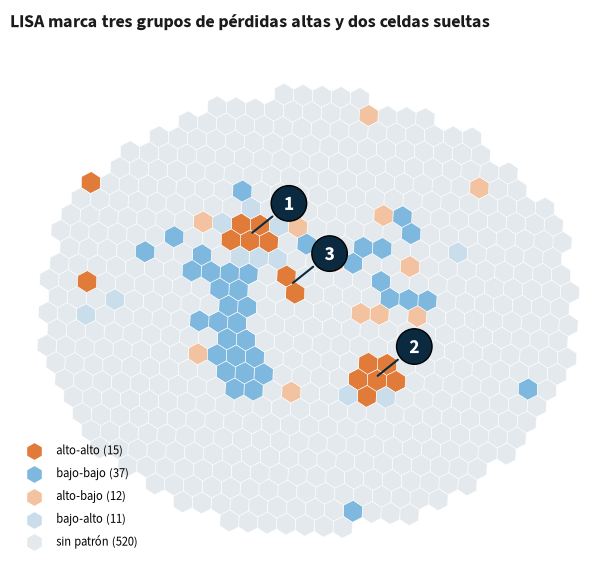

In [14]:
COLOR_LISA = {"alto-alto": estilo.NARANJA, "bajo-bajo": "#7FB8DE", "alto-bajo": "#F3C3A1",
              "bajo-alto": "#C9DDEB", "sin patrón": SIN_DATO}
fig, ax = plt.subplots(figsize=(8, 6.5))
pintar_mapa(ax, [COLOR_LISA[c] for c in celdas["lisa"]])
for g in grupos[grupos["grupo"] != "suelta"].itertuples():
    ax.annotate(g.grupo, xy=(g.x_km, g.y_km), xytext=(g.x_km + 2, g.y_km + 1.6), fontsize=14,
                weight="bold", color="white", ha="center", va="center",
                bbox={"boxstyle": "circle,pad=0.25", "fc": "#0B2A3F"},
                arrowprops={"arrowstyle": "-", "color": "#0B2A3F", "lw": 1.5})
for categoria, color in COLOR_LISA.items():
    ax.scatter([], [], marker="h", s=120, color=color, label=f"{categoria} ({(celdas['lisa'] == categoria).sum()})")
ax.legend(loc="lower left", fontsize=9)
ax.set_title("LISA marca tres grupos de pérdidas altas y dos celdas sueltas", loc="left", fontsize=13)
plt.show()

## 7. Ejercicio (en parejas, 35 min): ¿qué explica cada grupo?

El mapa de LISA no tiene ninguna capa de contexto: no sabemos **por qué** esos grupos pierden la
señal. Tenéis dos capas para cruzar con ellos:

- **Cobertura móvil:** `cobertura_dbm` (señal en dBm; cuanto más negativa, peor) y `cobertura`
  (buena, media o mala, que es −100 dBm o menos).
- **Emplazamiento:** `pasos_subterraneos`, `soportales` y `aparcamientos_subterraneos`.

La pregunta: **¿qué explica cada grupo? ¿Y por qué la zona con peor cobertura móvil no es punto
caliente?** Respuesta: una frase por grupo, con la capa que lo explica.

Pista: comparad cada grupo con el resto de la ciudad en todas las capas, y buscad dónde está la peor
cobertura móvil.

In [15]:
# Paso 1. Cada grupo frente al resto de la ciudad, capa a capa.
capa = "cobertura_dbm"  # ← probad también "pasos_subterraneos", "soportales" y "aparcamientos_subterraneos"

celdas.groupby("grupo")[capa].mean().round(2).to_frame(f"media de {capa}")

,media de cobertura_dbm
grupo,
1,"-100,00"
2,"-97,00"
3,"-87,50"
resto de la ciudad,"-86,59"
suelta,"-86,00"


In [16]:
# Paso 2. ¿Dónde está la peor cobertura móvil? ¿Es punto caliente?
n_peores = 10  # ← cuántas celdas con peor cobertura miramos

peores = celdas.nsmallest(n_peores, "cobertura_dbm")
# COMPLETAD: añadid a la lista las columnas que os ayuden a decidir si esta zona es un punto
# caliente y por qué (por ejemplo, la categoría LISA, la tasa suavizada o el emplazamiento).
peores[["barrio", "x", "y", "cobertura_dbm", "cobertura"]]

,barrio,x,y,cobertura_dbm,cobertura
502,Lonja 5,"8,82","-1,88",-113,mala
518,Lonja 5,"8,30","-2,70",-111,mala
519,Lonja 5,"9,27","-2,75",-109,mala
543,Lonja 5,"7,84","-1,82",-106,mala
506,Lonja 5,"8,36","-1,00",-105,mala
199,Ayuntamiento 3,"-3,64","3,94",-104,mala
545,Lonja 5,"7,32","-2,64",-104,mala
503,Lonja 5,"9,79","-1,93",-103,mala
198,Ayuntamiento 3,"-4,09","4,82",-102,mala
500,Lonja 5,"9,34","-1,05",-101,mala


In [17]:
# Paso 3 (opcional, para quien programa). ¿Cuánto multiplica la tasa cada capa?
# Pista: un modelo de Poisson de las pérdidas, con el logaritmo de los viajes como «exposición»
# (offset), con statsmodels: smf.glm(..., offset=np.log(viajes), family=sm.families.Poisson()).
# COMPLETAD

## Qué os lleváis

- **La unidad cambia la conclusión (MAUP).** Antes de creer «el problema está en tal distrito»,
  preguntad qué saldría por barrio o por hexágono.
- **Tasas, no conteos.** Sin denominador, el mapa es un mapa de dónde hay actividad.
- **Con pocos casos, la tasa exagera.** El suavizado bayesiano empírico templa las unidades pequeñas;
  sin él, el primero de la lista suele ser el que tuvo dos casos.
- **Moran dice si hay agrupación; LISA, dónde.** Y LISA hace cientos de pruebas: desconfiad de las
  celdas sueltas.
- **Una capa que coincide no es la causa.** Cruzad todas las capas y buscad dónde la explicación falla.

> Un mapa sin contraste espacial es una opinión con colores.